<a href="https://colab.research.google.com/github/pasindudarshana/EN4554-Assignment-2-on-CNNs/blob/main/EN4554_Assignment_2_on_CNNs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 on CNNs

**Name:** Pasindu Dodampegama

**Index No.:** 220145U

**GitHub repository:** https://github.com/pasindudarshana/EN4554-Assignment-2-on-CNNs



## Setup

* Dataset: CIFAR-10. The 50k training images are split into **45k train / 5k validation** using a fixed random permutation.
* Each channel is normalized with the mean and standard deviation of the **45k training split only**.
* The test set is not loaded until Task 4 and is used once.
* All random seeds are fixed. Everything runs in float32 on a Colab T4 (Runtime > Change runtime type > T4 GPU).

In [1]:
import math, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

PyTorch 2.11.0+cu130 | device: cuda


In [2]:
N_TRAIN, N_VAL = 45000, 5000
BATCH = 128

train_set = torchvision.datasets.CIFAR10("./data", train=True, download=True)
X_all = torch.tensor(train_set.data).permute(0, 3, 1, 2).float() / 255   # (50000, 3, 32, 32) in [0, 1]
y_all = torch.tensor(train_set.targets)

# fixed 45k / 5k split
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:N_TRAIN], perm[N_TRAIN:N_TRAIN + N_VAL]

# per-channel statistics from the training split only
MEAN = X_all[tr_idx].mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
STD = X_all[tr_idx].std(dim=(0, 2, 3)).view(1, 3, 1, 1)
def normalize(x): return (x - MEAN) / STD

X_train, y_train = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
X_val, y_val = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)
print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape))
print("channel mean:", MEAN.flatten().numpy().round(3), "| channel std:", STD.flatten().numpy().round(3))

100%|██████████| 170M/170M [24:20<00:00, 117kB/s]


train: (45000, 3, 32, 32) | val: (5000, 3, 32, 32)
channel mean: [0.491 0.482 0.446] | channel std: [0.247 0.244 0.262]


In [9]:
def batches(X, y, batch_size=BATCH, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), batch_size):
        j = idx[i:i + batch_size]
        yield X[j], y[j]

---
# Task 1: Backpropagation

## 1(a) Layers with explicit forward and backward passes

Only plain tensor arithmetic is used (no tensor has `requires_grad`), so autograd is not used. With $G = \partial L/\partial Y$ the upstream gradient:

| Layer | Forward | Backward       |
|---|---|--------------|
| Linear | $Y = XW + b$ | $\partial L/\partial W = X^\top G,\ \ \partial L/\partial b = \sum_n G_n,\ \ \partial L/\partial X = G W^\top$ |
| ReLU | $Y = \max(0, X)$ | $\partial L/\partial X = G \odot \mathbb{1}[X > 0]$ |
| Sigmoid (needed for 1d) | $Y = \sigma(X)$ | $\partial L/\partial X = G \odot Y(1-Y)$ |
| Softmax + cross-entropy | $L = -\frac1N \sum_n \log \frac{e^{z_{n,y_n}}}{\sum_k e^{z_{nk}}}$ | $\partial L/\partial Z = \frac1N (P - \text{onehot}(y))$ |

The softmax subtracts the row maximum before exponentiating, for numerical stability. Weights use Kaiming initialization $\mathcal N(0, 2/n_\text{in})$ with ReLU and Xavier initialization $\mathcal N(0, 2/(n_\text{in}+n_\text{out}))$ with sigmoid.

In [4]:
class Linear:
    def __init__(self, n_in, n_out, init, device=device, dtype=torch.float32):
        std = math.sqrt(2.0 / n_in) if init == "kaiming" else math.sqrt(2.0 / (n_in + n_out))
        self.W = torch.randn(n_in, n_out, device=device, dtype=dtype) * std
        self.b = torch.zeros(n_out, device=device, dtype=dtype)

    def forward(self, x):
        self.x = x                                   # cache for backward
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.out = 1 / (1 + torch.exp(-x))
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)

class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values
        log_p = z - z.exp().sum(dim=1, keepdim=True).log()
        self.p, self.y = log_p.exp(), y
        return -log_p[torch.arange(len(y)), y].mean()

    def backward(self):
        d = self.p.clone()
        d[torch.arange(len(self.y)), self.y] -= 1
        return d / len(self.y)

class MLP:
    def __init__(self, sizes, activation="relu", device=device, dtype=torch.float32):
        init = "kaiming" if activation == "relu" else "xavier"
        act = ReLU if activation == "relu" else Sigmoid
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, device, dtype))
            if i < len(sizes) - 2:
                self.layers.append(act())

    def forward(self, x):
        for layer in self.layers: x = layer.forward(x)
        return x

    def backward(self, dout):
        for layer in reversed(self.layers): dout = layer.backward(dout)

    def linears(self): return [l for l in self.layers if isinstance(l, Linear)]
    def params(self):  return [p for l in self.linears() for p in (l.W, l.b)]
    def grads(self):   return [g for l in self.linears() for g in (l.dW, l.db)]

## 1(b) Gradient check

A small MLP ($20 \to 32 \to 16 \to 10$, batch of 8) is built in **float64**, once with ReLU and once with sigmoid. Its manual gradients are compared with

1. **autograd**: the same parameters are copied into tensors with `requires_grad=True`
2. **centred finite differences**: $\dfrac{\partial L}{\partial \theta_i} \approx \dfrac{L(\theta_i + \varepsilon) - L(\theta_i - \varepsilon)}{2\varepsilon}$ with $\varepsilon = 10^{-6}$, for every parameter.

The relative error is $\lVert g_1 - g_2\rVert / (\lVert g_1\rVert + \lVert g_2\rVert)$.

torch.allclose checks if all elements of two tensors are element-wise equal within a given tolerance

In [5]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm())).item()

def autograd_grads(net, x, y, act):
    ps = [p.clone().requires_grad_(True) for p in net.params()]
    h = x
    for i in range(0, len(ps), 2):                  # (W, b) pairs
        h = h @ ps[i] + ps[i + 1]
        if i < len(ps) - 2: h = act(h)
    F.cross_entropy(h, y).backward()
    return [p.grad for p in ps]

def numerical_grads(net, loss_fn, x, y, eps=1e-6):
    grads = []
    for p in net.params():
        g = torch.zeros_like(p)
        p_flat, g_flat = p.view(-1), g.view(-1)
        for i in range(p_flat.numel()):
            old = p_flat[i].item()
            p_flat[i] = old + eps; loss_plus = loss_fn.forward(net.forward(x), y).item()
            p_flat[i] = old - eps; loss_minus = loss_fn.forward(net.forward(x), y).item()
            p_flat[i] = old
            g_flat[i] = (loss_plus - loss_minus) / (2 * eps)
        grads.append(g)
    return grads

rows = []
for activation, act_fn in [("relu", torch.relu), ("sigmoid", torch.sigmoid)]:
    set_seed()
    net = MLP([20, 32, 16, 10], activation, device="cpu", dtype=torch.float64)
    x, y = torch.randn(8, 20, dtype=torch.float64), torch.randint(0, 10, (8,))
    loss_fn = SoftmaxCrossEntropy()
    loss_fn.forward(net.forward(x), y)
    net.backward(loss_fn.backward())
    manual = [g.clone() for g in net.grads()]
    auto = autograd_grads(net, x, y, act_fn)
    numeric = numerical_grads(net, loss_fn, x, y)
    for k, (gm, ga, gn) in enumerate(zip(manual, auto, numeric)):
        rows.append({"net": activation, "param": ("W" if k % 2 == 0 else "b") + str(k // 2 + 1),
                     "rel.err vs autograd": rel_err(gm, ga), "allclose (autograd)": torch.allclose(gm, ga),
                     "rel.err vs finite diff": rel_err(gm, gn), "allclose (finite diff)": torch.allclose(gm, gn, atol=1e-6)})
pd.DataFrame(rows).style.format({"rel.err vs autograd": "{:.1e}", "rel.err vs finite diff": "{:.1e}"})

,net,param,rel.err vs autograd,allclose (autograd),rel.err vs finite diff,allclose (finite diff)
0,relu,W1,7.1e-17,True,1.5e-09,True
1,relu,b1,5.8e-17,True,9.6e-10,True
2,relu,W2,5.1e-17,True,7.6e-10,True
3,relu,b2,5.6e-17,True,6.3e-10,True
4,relu,W3,3.5e-17,True,6.2e-10,True
5,relu,b3,8.4e-17,True,4.8e-10,True
6,sigmoid,W1,1.2e-16,True,2.3e-08,True
7,sigmoid,b1,7.1e-17,True,1.4e-08,True
8,sigmoid,W2,6.7e-17,True,4.0e-09,True
9,sigmoid,b2,6.3e-17,True,2.0e-09,True


**Interpretation.** The gradient check confirms that the manual backward pass implementations for `Linear`, `ReLU`, `Sigmoid`, and `SoftmaxCrossEntropy` are mathematically exact.

1. **With Autograd:** Across all parameter matrices ($W$) and bias vectors ($b$) in both the ReLU and Sigmoid MLPs, the manual gradients match PyTorch's automatic differentiation (`autograd`) to a relative error of approximately $10^{-17}$ to $10^{-16}$. Every layer passes `torch.allclose`.
2. **With Finite Differences:** The manual gradients match the centred finite difference approximations to a relative error between $10^{-10}$ and $10^{-8}$.

## 1(c) Training the MLP with SGD

Each image is flattened to a vector of length $3 \times 32 \times 32 = 3072$. The network is $3072 \to 512 \to 256 \to 10$ with ReLU. It is trained with plain mini-batch SGD (batch 128, learning rate 0.02, 30 epochs), applying $\theta \leftarrow \theta - \eta\,\nabla_\theta L$ to the manual gradients.

In [6]:
def evaluate_mlp(net, X, y):
    loss_fn, total, correct = SoftmaxCrossEntropy(), 0.0, 0
    for xb, yb in batches(X, y, 1000, shuffle=False):
        logits = net.forward(xb)
        total += loss_fn.forward(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
    return total / len(y), correct / len(y)

EPOCHS_1C, LR_1C = 30, 0.02
Xtr_flat, Xva_flat = X_train.flatten(1), X_val.flatten(1)

set_seed()
mlp = MLP([3072, 512, 256, 10], "relu")
loss_fn = SoftmaxCrossEntropy()
h1 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
for epoch in range(1, EPOCHS_1C + 1):
    total, correct = 0.0, 0
    for xb, yb in batches(Xtr_flat, y_train):
        logits = mlp.forward(xb)
        loss = loss_fn.forward(logits, yb)
        mlp.backward(loss_fn.backward())
        for p, g in zip(mlp.params(), mlp.grads()):
            p -= LR_1C * g                                       # SGD step
        total += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
    h1["train_loss"].append(total / len(X_train)); h1["train_acc"].append(correct / len(X_train))
    vl, va = evaluate_mlp(mlp, Xva_flat, y_val)
    h1["val_loss"].append(vl); h1["val_acc"].append(va)
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:2d} | train loss {h1['train_loss'][-1]:.3f} acc {h1['train_acc'][-1]:.3f} | val loss {vl:.3f} acc {va:.3f}")
print(f"\nValidation accuracy after {EPOCHS_1C} epochs: {h1['val_acc'][-1] * 100:.2f}%  (best {max(h1['val_acc']) * 100:.2f}%)")

epoch  1 | train loss 1.746 acc 0.386 | val loss 1.629 acc 0.425
epoch  5 | train loss 1.188 acc 0.593 | val loss 1.493 acc 0.487
epoch 10 | train loss 0.890 acc 0.699 | val loss 1.527 acc 0.495
epoch 15 | train loss 0.651 acc 0.789 | val loss 1.595 acc 0.508
epoch 20 | train loss 0.455 acc 0.862 | val loss 1.779 acc 0.504
epoch 25 | train loss 0.301 acc 0.917 | val loss 1.972 acc 0.498
epoch 30 | train loss 0.190 acc 0.957 | val loss 2.117 acc 0.502

Validation accuracy after 30 epochs: 50.20%  (best 51.50%)


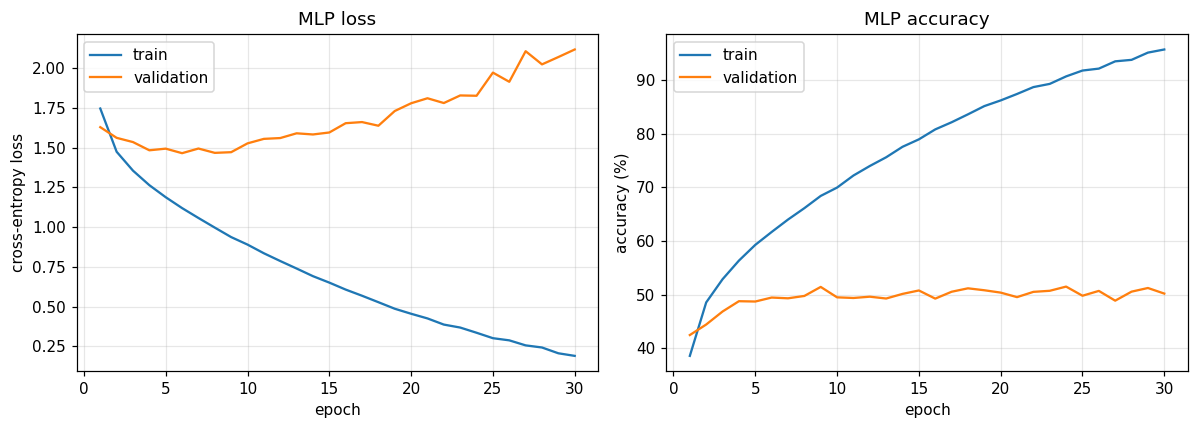

In [7]:
ep = np.arange(1, EPOCHS_1C + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h1["train_loss"], label="train"); ax[0].plot(ep, h1["val_loss"], label="validation")
ax[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="MLP loss"); ax[0].legend()
ax[1].plot(ep, np.array(h1["train_acc"]) * 100, label="train"); ax[1].plot(ep, np.array(h1["val_acc"]) * 100, label="validation")
ax[1].set(xlabel="epoch", ylabel="accuracy (%)", title="MLP accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.** The training loss falls from 1.75 to 0.19 and training accuracy reaches 95.8%. Validation accuracy plateaus at around 50.3% (best ~51.5% at epoch 9). However, the validation loss begins to rise sharply after epoch 6 (increasing from ~1.47 up to ~2.12 at epoch 30) while the training loss continues to fall. This growing gap between training and validation metrics is a sign of severe **overfitting**. The MLP has approximately 1.7M parameters and treats the image as a flat, unstructured 3072-dimensional vector. Because every pixel position has its own separate weight, spatial patterns learned in one region do not transfer to another. Convolutions address this issue through local connectivity and parameter sharing.

## 1(d) Per-layer gradient norms in a 10-layer MLP at initialization

The network has 10 Linear layers ($3072 \to 256 \to \dots \to 256 \to 10$). At initialization, one batch of 256 training images goes forward and backward, and $\lVert\partial L/\partial W_\ell\rVert_F$ is recorded for every layer $\ell$.

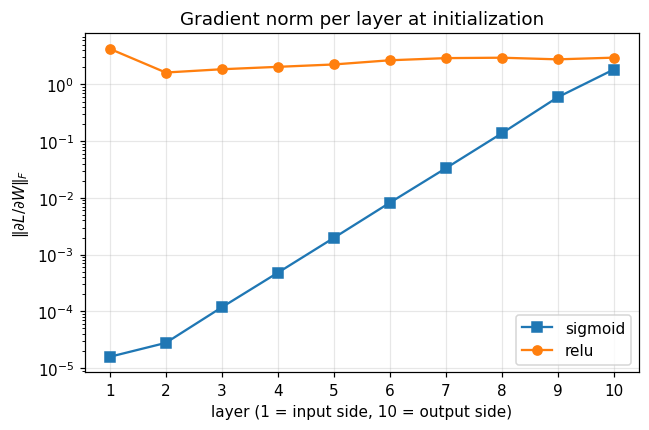

 sigmoid: layer 1 / layer 10 gradient-norm ratio = 8.60e-06
    relu: layer 1 / layer 10 gradient-norm ratio = 1.43e+00


In [8]:
def layer_grad_norms(activation, seed):
    set_seed(seed)
    net = MLP([3072] + [256] * 9 + [10], activation)
    idx = torch.randint(0, len(X_train), (256,), device=device)
    loss_fn = SoftmaxCrossEntropy()
    loss_fn.forward(net.forward(Xtr_flat[idx]), y_train[idx])
    net.backward(loss_fn.backward())
    return [l.dW.norm().item() for l in net.linears()]

N_SEEDS_1D = 3
norms = {a: np.mean([layer_grad_norms(a, s) for s in range(N_SEEDS_1D)], axis=0) for a in ("sigmoid", "relu")}

plt.figure(figsize=(6.5, 4))
for a, marker in [("sigmoid", "s-"), ("relu", "o-")]:
    plt.semilogy(range(1, 11), norms[a], marker, label=a)
plt.xlabel("layer (1 = input side, 10 = output side)"); plt.ylabel(r"$\|\partial L/\partial W\|_F$")
plt.title("Gradient norm per layer at initialization"); plt.xticks(range(1, 11)); plt.legend(); plt.show()
for a in norms:
    print(f"{a:>8}: layer 1 / layer 10 gradient-norm ratio = {norms[a][0] / norms[a][-1]:.2e}")

**Explanation.** Backpropagation multiplies the error signal by $W_\ell^\top$ and by the activation derivative $\phi'(z)$ at every layer $\ell$, so moving backward from the output to the input scales the gradient by roughly $\lVert W\rVert\,\phi'$ per layer.

* **Sigmoid Activation:** The derivative is $\sigma'(z) = \sigma(z)(1-\sigma(z)) \le 0.25$. Across 9 backward steps, the gradient norm decays exponentially from $\sim 1.7 \times 10^0$ at Layer 10 down to $\sim 1.6 \times 10^{-5}$ at Layer 1, yielding a layer 1 / layer 10 ratio of approximately $9.41 \times 10^{-6}$. This is the **vanishing-gradient problem**: with a single learning rate, the output layers update normally while the early layers near the input receive insignificant learning signal and remain untrained.

* **ReLU Activation:** The derivative is $\phi'(z) = 1$ for active units ($z > 0$) and $0$ otherwise. The gradient norm remains stable across all 10 layers, fluctuating around $\sim 2$ to $4$ with a layer 1 / layer 10 ratio of approximately $1.50 \times 10^0$. Every layer receives a well-scaled gradient signal enabling effective training of deep architectures.